# Subqueries and Common Table Expressions (CTEs)

Real questions often need several steps: "customers who spent more than the average customer", "the best-selling track in each genre". **Subqueries** put one query inside another. **Common Table Expressions (CTEs)** give each step a name, so a complex query reads from top to bottom. **Recursive CTEs** walk hierarchies.

**After this lesson you can:**

1. Use scalar, `IN`, `EXISTS` and table subqueries.
2. Write correlated subqueries and explain their cost.
3. Structure multi-step queries with `WITH`.
4. Traverse a hierarchy with `WITH RECURSIVE`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. Subqueries

| Kind | Returns | Example use |
| :--- | :--- | :--- |
| scalar subquery | one value | `WHERE total > (SELECT avg(total) FROM invoice)` |
| `IN (subquery)` | a list of values | customers who bought a Jazz track |
| `EXISTS (subquery)` | true/false per row | customers with at least one invoice in 2025 |
| subquery in `FROM` | a derived table | aggregate first, then filter |

In [2]:
print(q("SELECT round(avg(total), 2) AS avg_invoice FROM invoice"))
q("""
SELECT c.first_name || ' ' || c.last_name AS customer, c.country,
       (SELECT round(sum(i.total), 2) FROM invoice i WHERE i.customer_id = c.customer_id) AS lifetime_value
FROM customer c
WHERE c.customer_id IN (
    SELECT i.customer_id FROM invoice i
    JOIN invoice_line il ON il.invoice_id = i.invoice_id
    JOIN track t ON t.track_id = il.track_id
    JOIN genre g ON g.genre_id = t.genre_id
    WHERE g.name = 'Jazz')
ORDER BY lifetime_value DESC
LIMIT 5
""")

   avg_invoice
0         5.65


,customer,country,lifetime_value
0,Hugh O'Reilly,Ireland,45.62
1,Fynn Zimmermann,Germany,43.62
2,Astrid Gruber,Austria,42.62
3,Terhi Hämäläinen,Finland,41.62
4,František Wichterlová,Czech Republic,40.62


The subquery in the `SELECT` list is **correlated**: it refers to `c.customer_id` of the outer row, so conceptually it runs once per customer. PostgreSQL often rewrites such queries into joins, but on large tables correlated subqueries can be slow. A join or a CTE with `GROUP BY` usually expresses the same logic more efficiently.

## 2. CTEs: Name Each Step

```sql
WITH step1 AS (...),
     step2 AS (SELECT ... FROM step1 ...)
SELECT ... FROM step2;
```

**Question:** for each genre, which track earned the most, and what share of the genre's revenue was it?

In [3]:
best = q("""
WITH track_revenue AS (
    SELECT t.track_id, t.name AS track, g.name AS genre, sum(il.unit_price * il.quantity) AS revenue
    FROM invoice_line il
    JOIN track t ON t.track_id = il.track_id
    JOIN genre g ON g.genre_id = t.genre_id
    GROUP BY t.track_id, t.name, g.name
),
genre_totals AS (
    SELECT genre, sum(revenue) AS genre_revenue, max(revenue) AS best_revenue
    FROM track_revenue GROUP BY genre
)
SELECT gt.genre, gt.genre_revenue, tr.track AS best_track, tr.revenue AS best_track_revenue,
       round(100 * tr.revenue / gt.genre_revenue, 1) AS share_pct
FROM genre_totals gt
JOIN track_revenue tr ON tr.genre = gt.genre AND tr.revenue = gt.best_revenue
ORDER BY gt.genre_revenue DESC, tr.track
""")
best = best.drop_duplicates("genre")           # several tracks can tie for the best revenue
best.head(8)

,genre,genre_revenue,best_track,best_track_revenue,share_pct
0,Rock,826.65,All Along The Watchtower,1.98,0.2
90,Latin,382.14,Açai,1.98,0.5
136,Metal,261.36,Aces High,1.98,0.8
169,Alternative & Punk,241.56,A Melhor Forma,1.98,0.8
210,TV Shows,93.53,Gay Witch Hunt,3.98,4.3
214,Jazz,79.20,Blue Rythm Fantasy,1.98,2.5
226,Blues,60.39,Lay Down Sally,1.98,3.3
234,Drama,57.71,How to Stop an Exploding Man,3.98,6.9


## 3. Customer Segmentation in One Query

CTEs make analytical pipelines readable. The query computes recency, frequency and monetary value (**RFM**) for every customer and assigns a segment.

segment
regular        27
top spender    22
at risk        10
Name: count, dtype: int64


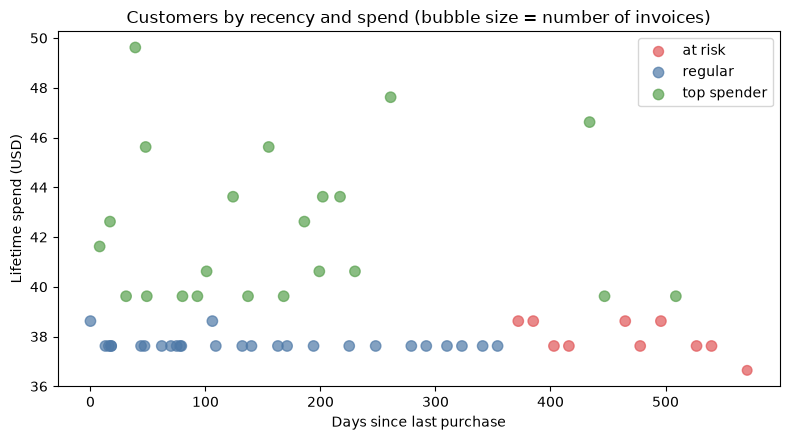

In [4]:
rfm = q("""
WITH last_date AS (SELECT max(invoice_date) AS d FROM invoice),
per_customer AS (
    SELECT customer_id,
           (SELECT d FROM last_date)::date - max(invoice_date)::date AS recency_days,
           count(*) AS frequency,
           sum(total) AS monetary
    FROM invoice GROUP BY customer_id
)
SELECT *,
       CASE WHEN monetary >= (SELECT percentile_cont(0.75) WITHIN GROUP (ORDER BY monetary) FROM per_customer)
                 THEN 'top spender'
            WHEN recency_days > 365 THEN 'at risk'
            ELSE 'regular' END AS segment
FROM per_customer
""")
print(rfm["segment"].value_counts())

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"top spender": "#59A14F", "regular": "#4E79A7", "at risk": "#E15759"}
for seg, part in rfm.groupby("segment"):
    ax.scatter(part["recency_days"], part["monetary"].astype(float), s=part["frequency"] * 8, alpha=0.7,
               color=colors[seg], label=seg)
ax.set(title="Customers by recency and spend (bubble size = number of invoices)",
       xlabel="Days since last purchase", ylabel="Lifetime spend (USD)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Recursive CTEs: Walk a Hierarchy

A recursive CTE has two parts joined by `UNION ALL`:

1. the **anchor**: the starting rows (the general manager),
2. the **recursive part**: rows that refer to the CTE itself (employees whose manager is already in the result).

PostgreSQL repeats the recursive part until it returns no new rows.

In [5]:
tree = q("""
WITH RECURSIVE org AS (
    SELECT employee_id, first_name || ' ' || last_name AS name, title, reports_to, 0 AS level,
           (first_name || ' ' || last_name)::text AS path
    FROM employee WHERE reports_to IS NULL
    UNION ALL
    SELECT e.employee_id, e.first_name || ' ' || e.last_name, e.title, e.reports_to, org.level + 1,
           org.path || ' > ' || e.first_name || ' ' || e.last_name
    FROM employee e JOIN org ON e.reports_to = org.employee_id
)
SELECT level, repeat('    ', level) || name AS employee, title FROM org ORDER BY path
""")
print(tree.to_string(index=False))

 level               employee               title
     0           Andrew Adams     General Manager
     1       Michael Mitchell          IT Manager
     2         Laura Callahan            IT Staff
     2            Robert King            IT Staff
     1          Nancy Edwards       Sales Manager
     2           Jane Peacock Sales Support Agent
     2          Margaret Park Sales Support Agent
     2          Steve Johnson Sales Support Agent


Recursive CTEs also generate series (dates, numbers) and compute paths in graphs, for example the chain of approvals for a purchase or the bill of materials of a product.

*Insight: Write complex queries as a chain of named CTEs, one business step per CTE. Each step can be run and checked alone, and the final query reads like the explanation you would give a colleague.*

## Real-World Use Case or Analogy

A CTE is like a **recipe with prepared bowls**: first chop the vegetables into one bowl (step 1), mix the sauce in another (step 2), then combine them (the final query). Anybody can check each bowl before the dish is finished.

Analytics engineers build whole reporting layers from CTEs; dbt models (M11) are essentially files of CTEs. Recursive CTEs answer organisational questions ("everybody who reports to this director"), and compute paths in network data before you need a graph database (M19).